In [32]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# Define o caminho subindo um nível 
path_csv = Path("../data/spotify-tracks/spotify-tracks-dataset.csv")

# Carrega os dados
df = pd.read_csv(path_csv)

print(f"✅ Dataset carregado com sucesso! Shape: {df.shape}")

✅ Dataset carregado com sucesso! Shape: (114000, 21)


In [34]:
# 1. Visão geral
print("--- PRIMEIRAS LINHAS ---")
display(df.head(3)) # display() deixa a tabela mais bonita no Jupyter

# 2. Tipos e Nulos
print("\n--- INFORMAÇÕES GERAIS ---")
df.info()

# 3. Verificando dados faltantes
print("\n--- % DE DADOS NULOS POR COLUNA ---")
nulos = (df.isna().sum() / len(df) * 100).round(2)
print(nulos[nulos > 0].sort_values(ascending=False)) # Mostra só as colunas que têm nulos

# 4. Duplicatas
print(f"\n--- DUPLICATAS ---")
print(f"Linhas 100% duplicadas: {df.duplicated().sum()}")
print(f"track_id duplicados: {df.duplicated(subset=['track_id']).sum()}")

# 5. Estatísticas das variáveis numéricas
print("\n--- ESTATÍSTICAS DESCRITIVAS ---")
display(df.describe().T)

# 6. Categorias (Gêneros)
print("\n--- GÊNEROS MUSICAIS ---")
print(f"Total de gêneros únicos: {df['track_genre'].nunique()}")
print("\nTop 10 gêneros com mais faixas:")
display(df['track_genre'].value_counts().head(10))

--- PRIMEIRAS LINHAS ---


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,...,-6.746,0,0.1430,0.0322,0.000001,0.358,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,...,-17.235,1,0.0763,0.9240,0.000006,0.101,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.359,...,-9.734,1,0.0557,0.2100,0.000000,0.117,0.120,76.332,4,acoustic



--- INFORMAÇÕES GERAIS ---
<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liv

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996



--- GÊNEROS MUSICAIS ---
Total de gêneros únicos: 114

Top 10 gêneros com mais faixas:


track_genre
acoustic       1000
afrobeat       1000
alt-rock       1000
alternative    1000
ambient        1000
anime          1000
black-metal    1000
bluegrass      1000
blues          1000
brazil         1000
Name: count, dtype: int64

In [35]:
# Cria a pasta interim se ela não existir
Path("../data/interim").mkdir(parents=True, exist_ok=True)

# Salva em formato Parquet (muito mais rápido e leve que CSV)
df.to_parquet("../data/interim/spotify_tracks_clean.parquet", index=False)

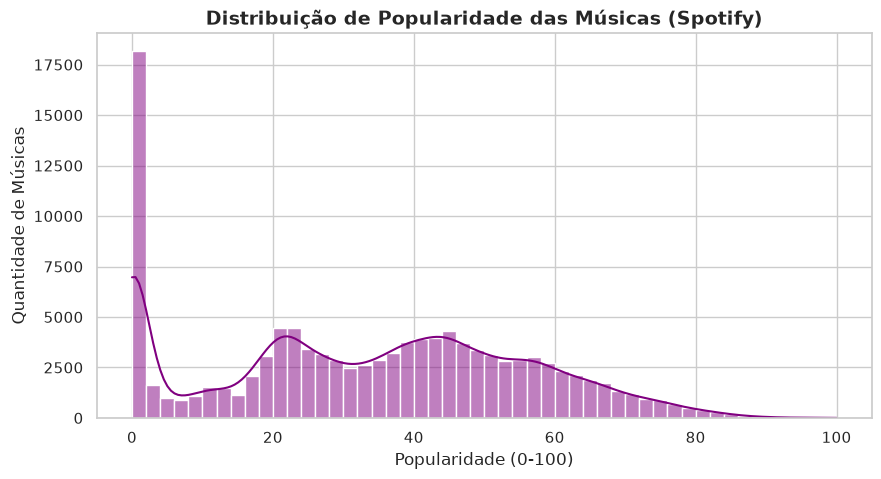

In [36]:
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(10, 5))

# Histograma da popularidade
sns.histplot(df['popularity'], bins=50, kde=True, color='purple')
plt.title('Distribuição de Popularidade das Músicas (Spotify)', fontsize=14, fontweight='bold')
plt.xlabel('Popularidade (0-100)')
plt.ylabel('Quantidade de Músicas')
plt.show()

/tmp/ipykernel_4381/1131183002.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_generos.values, y=top_generos.index, palette="viridis")


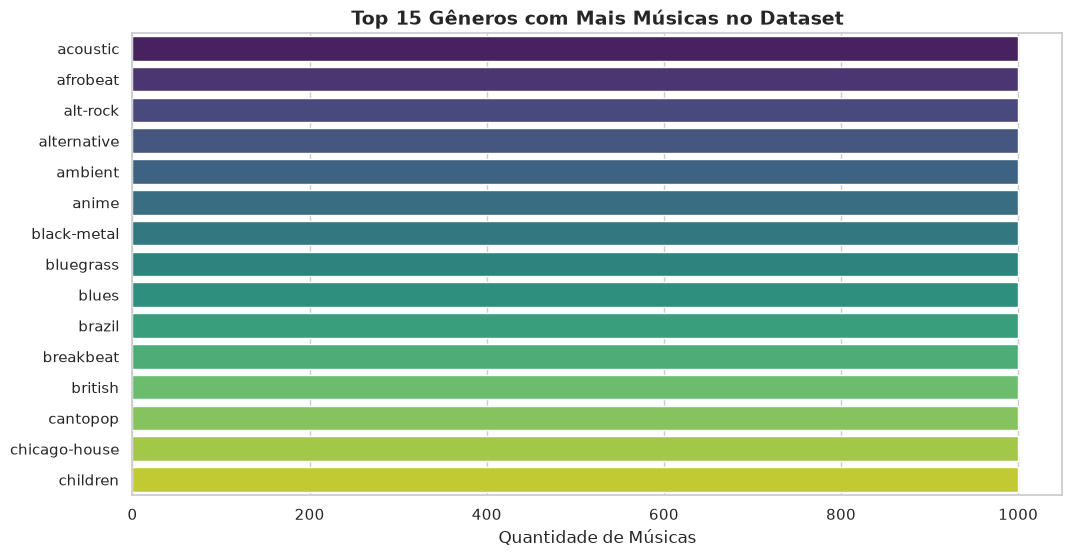

In [44]:
plt.figure(figsize=(12, 6))
# Top 15 gêneros por quantidade de músicas
top_generos = df['track_genre'].value_counts().head(15)
sns.barplot(x=top_generos.values, y=top_generos.index, palette="viridis")
plt.title('Top 15 Gêneros com Mais Músicas no Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de Músicas')
plt.ylabel('')
plt.show()

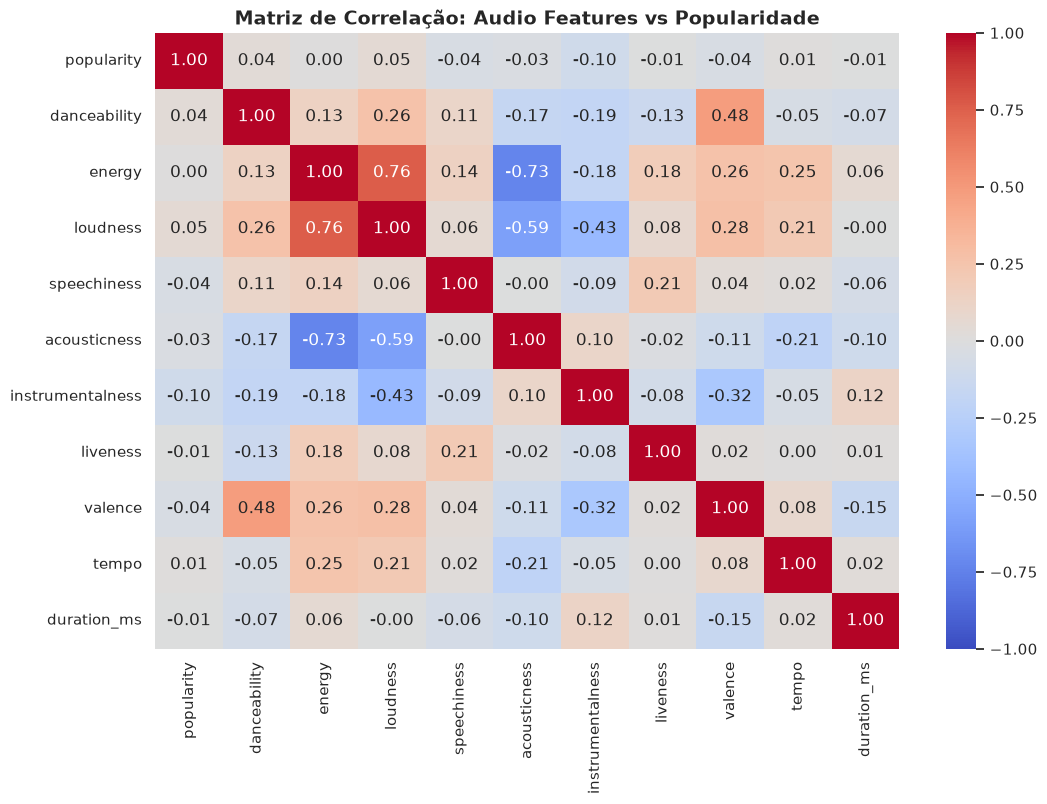

In [45]:
colunas_audio = ['popularity', 'danceability', 'energy', 'loudness', 'speechiness', 
                 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

plt.figure(figsize=(12, 8))
correlacao = df[colunas_audio].corr()

# Criando um heatmap
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação: Audio Features vs Popularidade', fontsize=14, fontweight='bold')
plt.show()